In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_excel("2023.xlsx")
df = df[df["x4"] > 0]
df = df[~df["regions"].isin(["Московская область", "Город Москва столица Российской Федерации город федерального значения", "Республика Саха (Якутия)"])].set_index('regions')
df.shape

(72, 4)

In [3]:
df_with_clusters = df.copy()

In [4]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

for i in df.columns:
    df[i] = df_scaled[:, 0] 

df.head()

,x1,x2,x3,x4
regions,,,,
Алтайский край,-0.829136,-0.829136,-0.829136,-0.829136
Амурская область,-1.652357,-1.652357,-1.652357,-1.652357
Архангельская область,-1.600906,-1.600906,-1.600906,-1.600906
Астраханская область,0.880191,0.880191,0.880191,0.880191
Белгородская область,2.017836,2.017836,2.017836,2.017836


In [5]:
df_with_clusters = df.copy()

In [6]:
agg_cluster = AgglomerativeClustering(n_clusters=5, linkage='ward')
df_with_clusters["clusters"] = agg_cluster.fit_predict(df)

In [15]:
df_with_clusters.groupby(by = ["clusters"]).count() 

,x1,x2,x3,x4
clusters,,,,
0,24,24,24,24
1,22,22,22,22
2,10,10,10,10
3,8,8,8,8
4,8,8,8,8


In [23]:
df_with_clusters[df_with_clusters['clusters'] == 0]

,x1,x2,x3,x4,clusters
regions,,,,,
Астраханская область,0.880191,0.880191,0.880191,0.880191,0
Владимирская область,0.542327,0.542327,0.542327,0.542327,0
Воронежская область,0.920208,0.920208,0.920208,0.920208,0
Калининградская область,0.520031,0.520031,0.520031,0.520031,0
Липецкая область,0.268492,0.268492,0.268492,0.268492,0
Мурманская область,0.920208,0.920208,0.920208,0.920208,0
Орловская область,0.542327,0.542327,0.542327,0.542327,0
Пензенская область,0.354244,0.354244,0.354244,0.354244,0
Республика Калмыкия,0.674385,0.674385,0.674385,0.674385,0


In [9]:
df_with_clusters.reset_index().shape

(72, 6)

In [22]:
df_with_clusters[df_with_clusters.clusters == 0]

,x1,x2,x3,x4,clusters
regions,,,,,
Астраханская область,0.880191,0.880191,0.880191,0.880191,0
Владимирская область,0.542327,0.542327,0.542327,0.542327,0
Воронежская область,0.920208,0.920208,0.920208,0.920208,0
Калининградская область,0.520031,0.520031,0.520031,0.520031,0
Липецкая область,0.268492,0.268492,0.268492,0.268492,0
Мурманская область,0.920208,0.920208,0.920208,0.920208,0
Орловская область,0.542327,0.542327,0.542327,0.542327,0
Пензенская область,0.354244,0.354244,0.354244,0.354244,0
Республика Калмыкия,0.674385,0.674385,0.674385,0.674385,0


<Axes: >

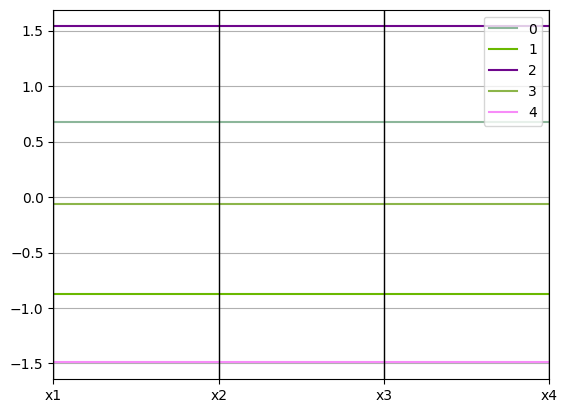

In [11]:
df_with_means = df_with_clusters.groupby(by = ["clusters"]).mean().reset_index()
pd.plotting.parallel_coordinates(df_with_means, "clusters")

{'icoord': [[25.0, 25.0, 35.0, 35.0],
  [15.0, 15.0, 30.0, 30.0],
  [65.0, 65.0, 75.0, 75.0],
  [55.0, 55.0, 70.0, 70.0],
  [45.0, 45.0, 62.5, 62.5],
  [85.0, 85.0, 95.0, 95.0],
  [105.0, 105.0, 115.0, 115.0],
  [135.0, 135.0, 145.0, 145.0],
  [125.0, 125.0, 140.0, 140.0],
  [110.0, 110.0, 132.5, 132.5],
  [90.0, 90.0, 121.25, 121.25],
  [155.0, 155.0, 165.0, 165.0],
  [185.0, 185.0, 195.0, 195.0],
  [175.0, 175.0, 190.0, 190.0],
  [160.0, 160.0, 182.5, 182.5],
  [205.0, 205.0, 215.0, 215.0],
  [225.0, 225.0, 235.0, 235.0],
  [210.0, 210.0, 230.0, 230.0],
  [255.0, 255.0, 265.0, 265.0],
  [245.0, 245.0, 260.0, 260.0],
  [220.0, 220.0, 252.5, 252.5],
  [171.25, 171.25, 236.25, 236.25],
  [105.625, 105.625, 203.75, 203.75],
  [53.75, 53.75, 154.6875, 154.6875],
  [22.5, 22.5, 104.21875, 104.21875],
  [285.0, 285.0, 295.0, 295.0],
  [305.0, 305.0, 315.0, 315.0],
  [290.0, 290.0, 310.0, 310.0],
  [275.0, 275.0, 300.0, 300.0],
  [355.0, 355.0, 365.0, 365.0],
  [345.0, 345.0, 360.0, 360.0],


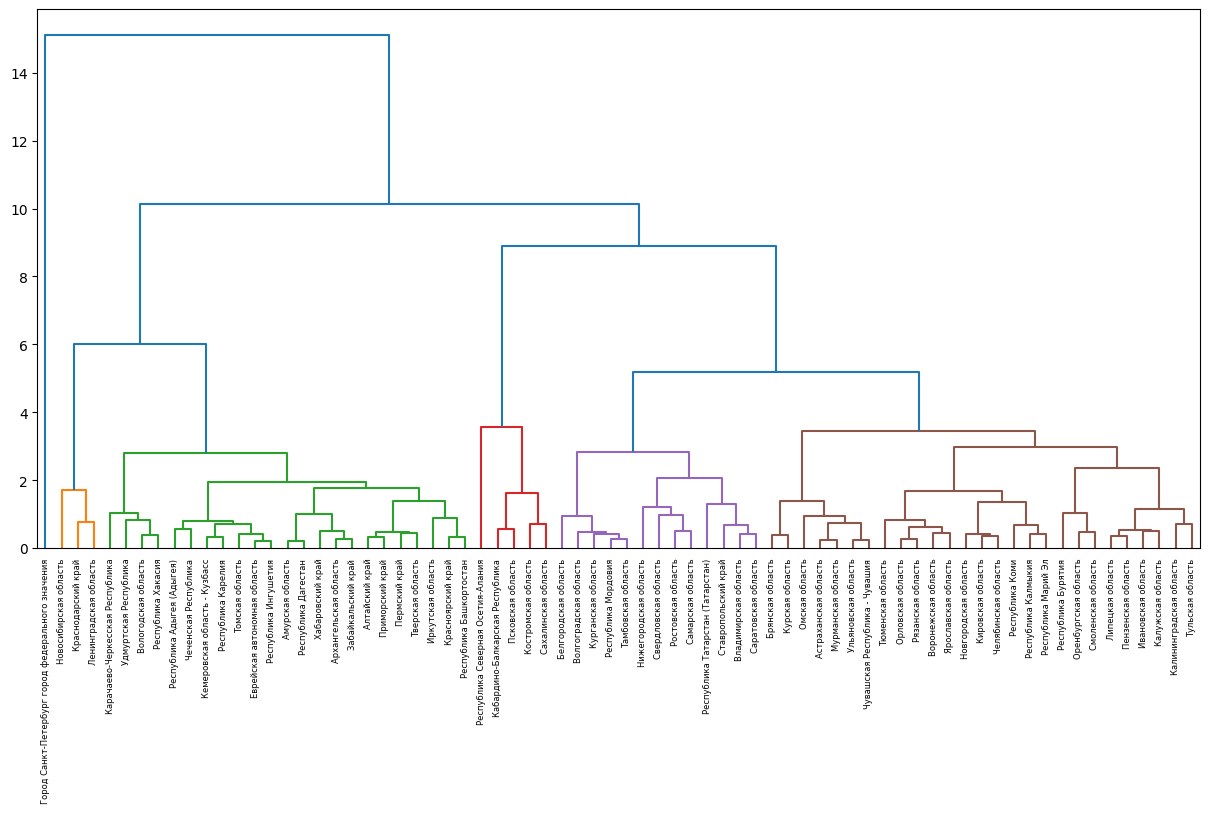

In [13]:
Z = linkage(df_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(15, 7))
dendrogram(Z, color_threshold=4, orientation="top", labels = df.index)

In [121]:
df_with_clusters

,x1,x2,x3,x4,clusters
regions,,,,,
Алтайский край,-0.833573,-0.833573,-0.833573,-0.833573,3
Амурская область,-2.019004,-2.019004,-2.019004,-2.019004,0
Архангельская область,-1.745080,-1.745080,-1.745080,-1.745080,0
Астраханская область,0.493543,0.493543,0.493543,0.493543,4
Белгородская область,1.263364,1.263364,1.263364,1.263364,1
...,...,...,...,...,...
Хабаровский край,-1.456987,-1.456987,-1.456987,-1.456987,0
Челябинская область,0.021259,0.021259,0.021259,0.021259,2
Чеченская Республика,-1.395590,-1.395590,-1.395590,-1.395590,0
